In [1]:
import os

# Set thread limits before importing NumPy or scikit-learn.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

print(f"Python runtime ready | scikit-learn {sklearn.__version__}")

Python runtime ready | scikit-learn 1.9.1


# Support Vector Machine on the Iris Dataset

This notebook loads scikit-learn's built-in Iris dataset, explores its features, and trains an SVM with a stratified 70/30 train/test split. A pipeline standardizes the features, projects them to two principal components, and fits the classifier; the same fitted model is used for evaluation and the decision-boundary visualization.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()
class_names = list(iris.target_names)

iris_df = X.copy()
iris_df["species"] = y.map(dict(enumerate(class_names)))

print(f"Rows: {len(iris_df)} | Features: {X.shape[1]} | Classes: {len(class_names)}")
display(iris_df.head())
print("\nFeature summary:")
display(X.describe().T)
print(f"\nMissing values: {int(X.isna().sum().sum())}")
print(f"Duplicate rows: {int(iris_df.duplicated().sum())}")

Rows: 150 | Features: 4 | Classes: 3


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Feature summary:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5



Missing values: 0
Duplicate rows: 1


## Exploratory Data Analysis

Check class balance, feature relationships, and the overall correlation structure before modeling.

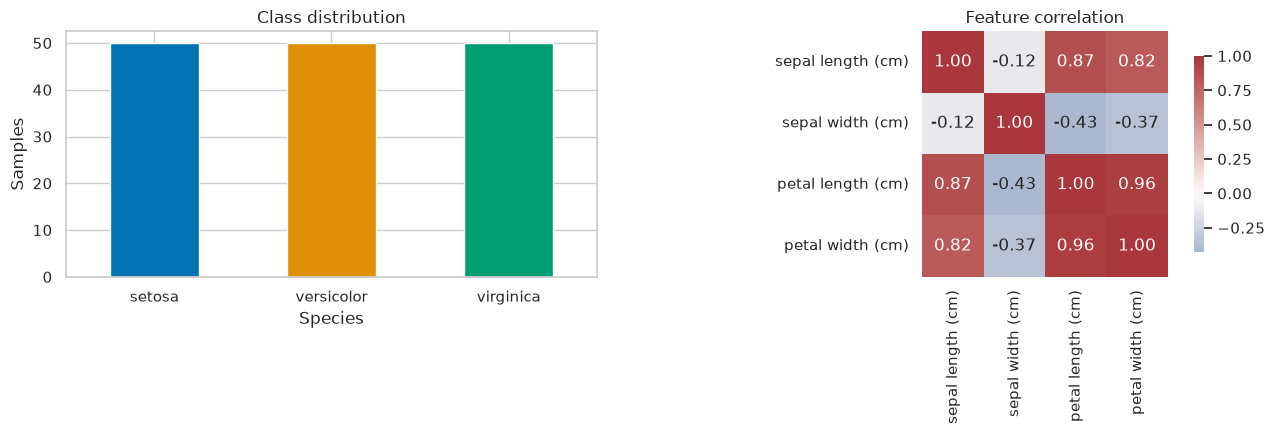

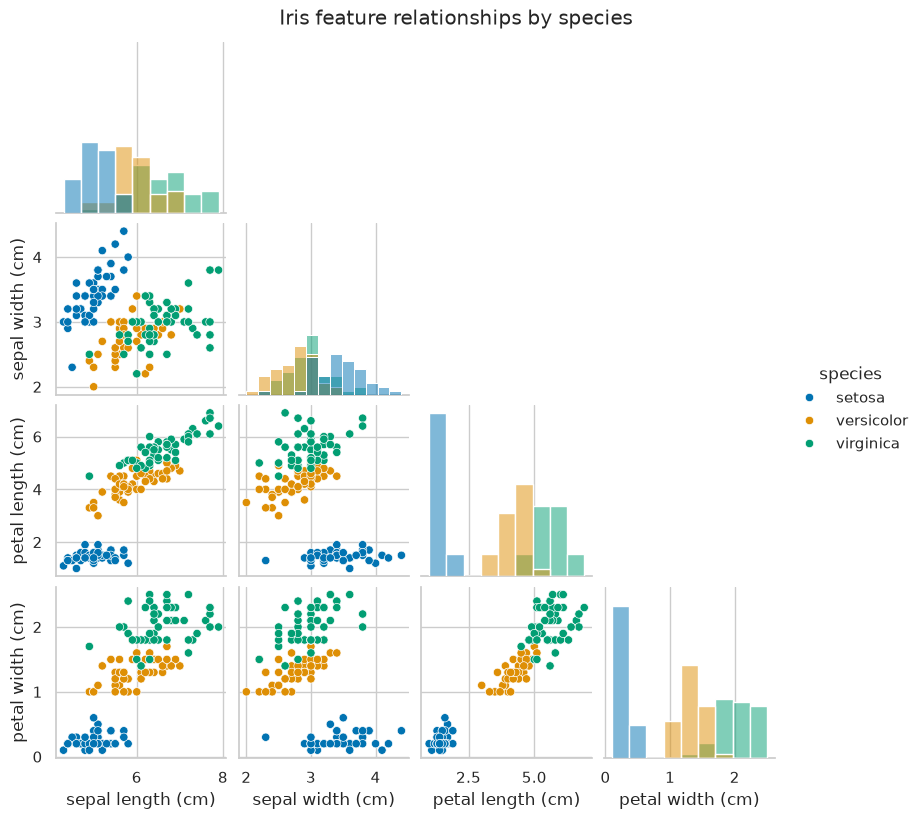

In [3]:
sns.set_theme(style="whitegrid", palette="colorblind")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
iris_df["species"].value_counts().reindex(class_names).plot(
    kind="bar", ax=axes[0], color=sns.color_palette("colorblind", n_colors=3)
)
axes[0].set(title="Class distribution", xlabel="Species", ylabel="Samples")
axes[0].tick_params(axis="x", rotation=0)

sns.heatmap(
    X.corr(), annot=True, fmt=".2f", cmap="vlag", center=0,
    square=True, ax=axes[1], cbar_kws={"shrink": 0.8}
)
axes[1].set_title("Feature correlation")
fig.tight_layout()
plt.show()

pair_plot = sns.pairplot(
    iris_df, vars=list(X.columns), hue="species", corner=True,
    diag_kind="hist", height=2.0
)
pair_plot.fig.suptitle("Iris feature relationships by species", y=1.02)
plt.show()

## Train/Test Split and Preprocessing

Keep 30% of the data for testing while preserving class proportions. Scaling and PCA are inside the pipeline so they learn parameters from the training data only.

In [4]:
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("svc", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

print(f"Training samples: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Testing samples:  {len(X_test)} ({len(X_test) / len(X):.0%})")
print("Class counts in test set:")
print(y_test.map(dict(enumerate(class_names))).value_counts().reindex(class_names))

Training samples: 105 (70%)
Testing samples:  45 (30%)
Class counts in test set:
target
setosa        15
versicolor    15
virginica     15
Name: count, dtype: int64


## Fit and Evaluate

Test accuracy: 0.911

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45



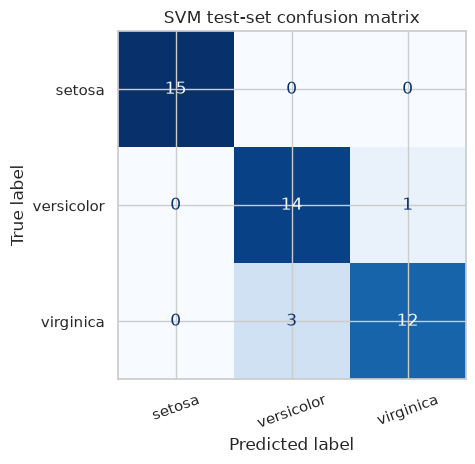

Explained variance by PCA components: [0.726 0.234]
Total variance retained: 96.0%


In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

conf_matrix = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names).plot(
    cmap="Blues", values_format="d", colorbar=False
)
plt.title("SVM test-set confusion matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

pca = svm_model.named_steps["pca"]
print("Explained variance by PCA components:", np.round(pca.explained_variance_ratio_, 3))
print(f"Total variance retained: {pca.explained_variance_ratio_.sum():.1%}")

## Model Visualization

The plot shows the fitted SVC's decision regions in the two PCA components. Both train and test samples are transformed with the scaler and PCA fitted on the training split; outlined circles identify the SVC support vectors.

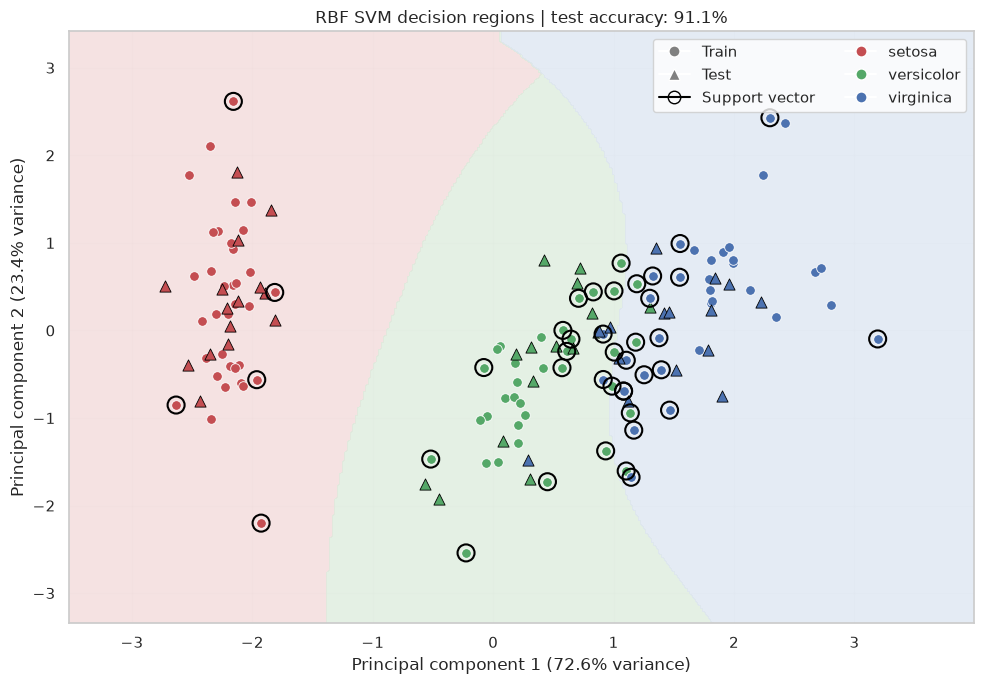

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

scaler = svm_model.named_steps["scaler"]
pca = svm_model.named_steps["pca"]
svc = svm_model.named_steps["svc"]
X_train_pca = pca.transform(scaler.transform(X_train))
X_test_pca = pca.transform(scaler.transform(X_test))

padding = 0.8
x_min = min(X_train_pca[:, 0].min(), X_test_pca[:, 0].min()) - padding
x_max = max(X_train_pca[:, 0].max(), X_test_pca[:, 0].max()) + padding
y_min = min(X_train_pca[:, 1].min(), X_test_pca[:, 1].min()) - padding
y_max = max(X_train_pca[:, 1].max(), X_test_pca[:, 1].max()) + padding
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350),
)
grid = np.column_stack([xx.ravel(), yy.ravel()])
regions = svc.predict(grid).reshape(xx.shape)

class_colors = ["#c44e52", "#55a868", "#4c72b0"]
region_colors = ["#f2d9d9", "#dcebdc", "#dce5f1"]
fig, ax = plt.subplots(figsize=(10, 7))
ax.contourf(
    xx, yy, regions, levels=np.arange(len(class_names) + 1) - 0.5,
    cmap=ListedColormap(region_colors), alpha=0.75
)

for class_id, class_name in enumerate(class_names):
    class_color = class_colors[class_id]
    train_mask = y_train.to_numpy() == class_id
    test_mask = y_test.to_numpy() == class_id
    ax.scatter(
        X_train_pca[train_mask, 0], X_train_pca[train_mask, 1],
        color=class_color, marker="o", edgecolor="white", linewidth=0.6, s=48
    )
    ax.scatter(
        X_test_pca[test_mask, 0], X_test_pca[test_mask, 1],
        color=class_color, marker="^", edgecolor="black", linewidth=0.6, s=65
    )

support_vectors = svc.support_vectors_
ax.scatter(
    support_vectors[:, 0], support_vectors[:, 1],
    facecolors="none", edgecolors="black", linewidths=1.5, s=150, zorder=4
)
ax.set(
    xlabel=f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
    ylabel=f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
    title=f"RBF SVM decision regions | test accuracy: {accuracy_score(y_test, y_pred):.1%}",
)
legend_items = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", label="Train", markersize=8),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="gray", label="Test", markersize=8),
    Line2D([0], [0], marker="o", color="black", markerfacecolor="none", label="Support vector", markersize=9),
]
legend_items.extend(
    Line2D([0], [0], marker="o", color="w", markerfacecolor=class_colors[index],
           label=class_name, markersize=8)
    for index, class_name in enumerate(class_names)
)
ax.legend(handles=legend_items, loc="best", frameon=True, ncol=2)
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()